In [8]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity

import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("All libraries imported successfully!")


All libraries imported successfully!


In [5]:
df = pd.read_csv(r"D:\Data Science\Project\Mobiles Reviews\Mobile Reviews Sentiment null.csv")


# Inspect the dataset
print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDataset information:")
df.info()


Dataset shape: (50000, 22)

First five rows:


,review_id,customer_name,age,brand,model,price_usd,price_local,currency,exchange_rate_to_usd,rating,...,language,review_date,verified_purchase,battery_life_rating,camera_rating,performance_rating,design_rating,display_rating,helpful_votes,source
0,1,Aryan Maharaj,45,Realme,Realme 12 Pro,337.31,₹27996.73,INR,83.00,2.0,...,Hindi,11/6/2023,True,1,1,3,2,1,1,Amazon
1,2,Davi Miguel Sousa,18,Realme,Realme 12 Pro,307.78,R$1754.35,BRL,5.70,4.0,...,Portuguese,3/30/2023,True,3,2,4,3,2,5,Flipkart
2,3,Pahal Balay,27,Google,Pixel 6,864.53,₹71755.99,INR,83.00,4.0,...,Hindi,12/7/2022,True,3,5,3,2,4,8,AliExpress
3,4,David Guzman,19,Xiaomi,Redmi Note 13,660.94,د.إ2425.65,AED,3.67,3.0,...,English,3/11/2025,False,1,3,2,1,2,3,Amazon
4,5,Yago Leão,38,Motorola,Edge 50,792.13,R$4515.14,BRL,5.70,3.0,...,Portuguese,9/29/2023,True,3,3,2,2,1,0,BestBuy



Column names:
['review_id', 'customer_name', 'age', 'brand', 'model', 'price_usd', 'price_local', 'currency', 'exchange_rate_to_usd', 'rating', 'sentiment', 'country', 'language', 'review_date', 'verified_purchase', 'battery_life_rating', 'camera_rating', 'performance_rating', 'design_rating', 'display_rating', 'helpful_votes', 'source']

Data types:
review_id                 int64
customer_name               str
age                       int64
brand                       str
model                       str
price_usd               float64
price_local                 str
currency                    str
exchange_rate_to_usd    float64
rating                  float64
sentiment                   str
country                     str
language                    str
review_date                 str
verified_purchase          bool
battery_life_rating       int64
camera_rating             int64
performance_rating        int64
design_rating             int64
display_rating            int64
helpfu

In [6]:

# Missing-value analysis
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
].sort_values(
    "Missing_Count",
    ascending=False
)

display(missing_summary)

# Check the number of brands and models
print("Unique brands:", df["brand"].nunique())
print("Unique models:", df["model"].nunique())

print("\nReviews per brand:")
display(df["brand"].value_counts())

print("\nReviews per model:")
display(df["model"].value_counts())

# Inspect records with missing ratings
display(
    df[df["rating"].isnull()][
        ["brand", "model", "price_usd", "rating", "sentiment"]
    ].head(10)
)


,Missing_Count,Missing_Percentage
rating,2453,4.91
price_usd,2450,4.90
source,2448,4.90
sentiment,2445,4.89
price_local,2431,4.86


Unique brands: 7
Unique models: 22

Reviews per brand:


brand
Xiaomi      7241
Google      7234
Apple       7144
OnePlus     7136
Realme      7132
Motorola    7061
Samsung     7052
Name: count, dtype: int64


Reviews per model:


model
Realme Narzo 70    3597
Realme 12 Pro      3535
Redmi Note 13      2470
Pixel 7a           2468
Mi 13 Pro          2445
OnePlus 11R        2433
Razr 40            2395
Pixel 8            2387
OnePlus Nord 3     2380
Pixel 6            2379
Moto G Power       2351
Poco X6            2326
OnePlus 12         2323
Edge 50            2315
iPhone SE          1796
iPhone 15 Pro      1793
Galaxy Note 20     1789
iPhone 14          1788
Galaxy A55         1788
iPhone 13          1767
Galaxy S24         1761
Galaxy Z Flip      1714
Name: count, dtype: int64

,brand,model,price_usd,rating,sentiment
69,Google,Pixel 7a,822.18,NaN,NaN
73,Motorola,Edge 50,656.62,NaN,Positive
87,Xiaomi,Mi 13 Pro,NaN,NaN,Neutral
129,Apple,iPhone 15 Pro,752.16,NaN,Positive
137,OnePlus,OnePlus 12,597.26,NaN,Negative
144,OnePlus,OnePlus 11R,574.40,NaN,Positive
165,Google,Pixel 7a,796.29,NaN,Positive
169,Xiaomi,Mi 13 Pro,368.67,NaN,Positive
224,Google,Pixel 7a,751.16,NaN,Positive
249,Xiaomi,Mi 13 Pro,593.69,NaN,Positive


In [9]:

duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)


Duplicate rows: 0


In [10]:

df_clean = df.copy()

print("Working copy created.")
print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)


Working copy created.
Original dataset shape: (50000, 22)
Working dataset shape: (50000, 22)


In [12]:

df_clean["source"] = df_clean["source"].fillna("Unknown")

print(
    "Missing source values:",
    df_clean["source"].isnull().sum()
)


Missing source values: 0


In [13]:

price_missing_pattern = pd.crosstab(
    df_clean["price_usd"].isnull(),
    df_clean["price_local"].isnull(),
    rownames=["USD price missing"],
    colnames=["Local price missing"]
)

display(price_missing_pattern)

print(
    "Both prices missing:",
    (
        df_clean["price_usd"].isnull()
        & df_clean["price_local"].isnull()
    ).sum()
)

print(
    "USD price missing:",
    df_clean["price_usd"].isnull().sum()
)

print(
    "Local price missing:",
    df_clean["price_local"].isnull().sum()
)


Local price missing,False,True
USD price missing,,
False,45242,2308
True,2327,123


Both prices missing: 123
USD price missing: 2450
Local price missing: 2431


In [14]:

numeric_columns = df_clean.select_dtypes(
    include=np.number
).columns.tolist()

display(df_clean[numeric_columns].describe().T)

print("Negative USD prices:",
      (df_clean["price_usd"] < 0).sum())

print("Zero USD prices:",
      (df_clean["price_usd"] == 0).sum())

print("Ratings outside the 1–5 range:",
      (
          df_clean["rating"].notna()
          & ~df_clean["rating"].between(1, 5)
      ).sum())


,count,mean,std,min,25%,50%,75%,max
review_id,50000.0,25000.500000,14433.901067,1.00,12500.750,25000.500,37500.2500,50000.00
age,50000.0,30.075220,8.931307,18.00,23.000,29.000,36.0000,65.00
price_usd,47550.0,689.892770,310.327220,180.02,450.755,637.585,901.4575,1499.89
exchange_rate_to_usd,50000.0,12.057946,26.553332,0.78,1.000,1.530,5.7000,83.00
rating,47547.0,3.123415,1.249067,1.00,2.000,3.000,4.0000,5.00
battery_life_rating,50000.0,2.718000,1.348270,1.00,1.000,3.000,4.0000,5.00
camera_rating,50000.0,2.717640,1.345001,1.00,1.000,3.000,4.0000,5.00
performance_rating,50000.0,2.719620,1.349208,1.00,1.000,3.000,4.0000,5.00
design_rating,50000.0,2.713960,1.343346,1.00,1.000,3.000,4.0000,5.00
display_rating,50000.0,2.721280,1.352121,1.00,1.000,3.000,4.0000,5.00


Negative USD prices: 0
Zero USD prices: 0
Ratings outside the 1–5 range: 0


In [15]:

df_clean["review_date"] = pd.to_datetime(
    df_clean["review_date"],
    errors="coerce"
)

print("Review date data type:", df_clean["review_date"].dtype)
print("Missing or invalid dates:", df_clean["review_date"].isnull().sum())


Review date data type: datetime64[us]
Missing or invalid dates: 0


In [16]:

duplicates_before = df_clean.duplicated().sum()

print("Exact duplicates before cleaning:", duplicates_before)

df_clean = df_clean.drop_duplicates().copy()

print("Dataset shape after duplicate removal:", df_clean.shape)


Exact duplicates before cleaning: 0
Dataset shape after duplicate removal: (50000, 22)


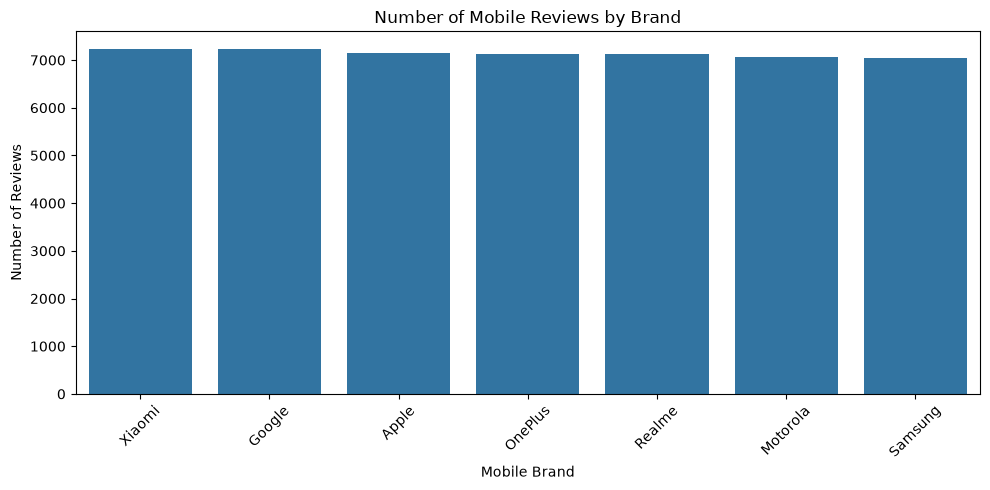

In [17]:

brand_counts = df_clean["brand"].value_counts()

plt.figure(figsize=(10, 5))
sns.barplot(
    x=brand_counts.index,
    y=brand_counts.values
)

plt.title("Number of Mobile Reviews by Brand")
plt.xlabel("Mobile Brand")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


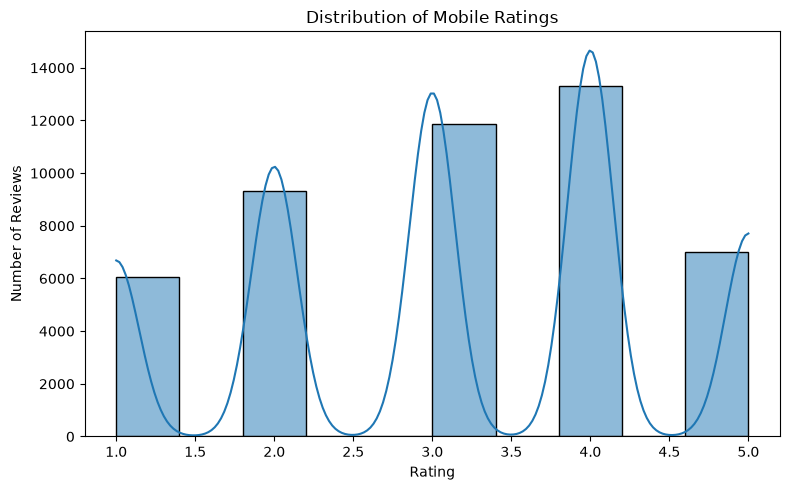

In [18]:

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="rating",
    bins=10,
    kde=True
)

plt.title("Distribution of Mobile Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


,brand,Average_Rating,Review_Count
4,Realme,3.14,6793
0,Apple,3.13,6778
3,OnePlus,3.13,6803
1,Google,3.12,6853
6,Xiaomi,3.11,6871
5,Samsung,3.11,6729
2,Motorola,3.11,6720


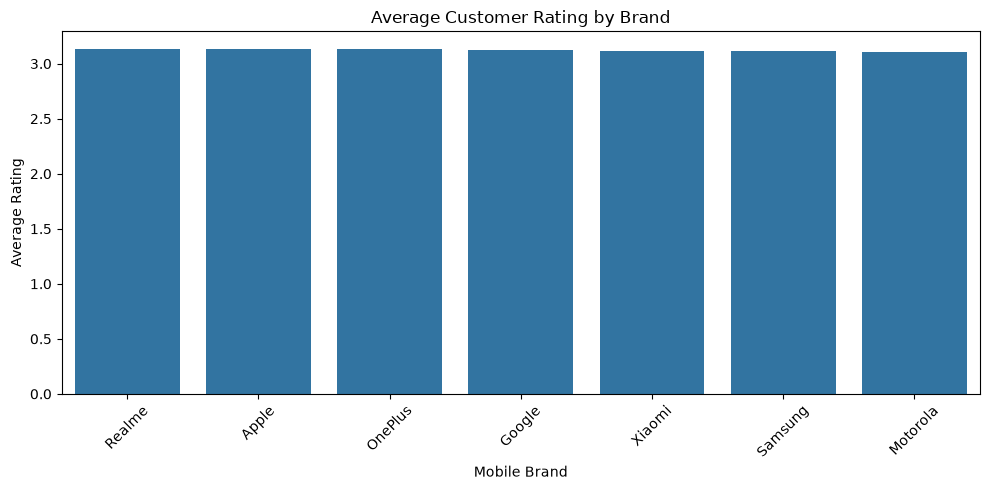

In [19]:

brand_ratings = (
    df_clean.groupby("brand", as_index=False)
    .agg(
        Average_Rating=("rating", "mean"),
        Review_Count=("rating", "count")
    )
    .sort_values("Average_Rating", ascending=False)
)

display(brand_ratings.round(2))

plt.figure(figsize=(10, 5))

sns.barplot(
    data=brand_ratings,
    x="brand",
    y="Average_Rating"
)

plt.title("Average Customer Rating by Brand")
plt.xlabel("Mobile Brand")
plt.ylabel("Average Rating")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


,brand,Average_Price_USD,Median_Price_USD
0,Apple,1103.15,1101.38
5,Samsung,900.50,902.30
1,Google,805.13,805.76
3,OnePlus,672.16,668.36
2,Motorola,506.54,509.72
6,Xiaomi,449.75,448.44
4,Realme,393.23,394.91


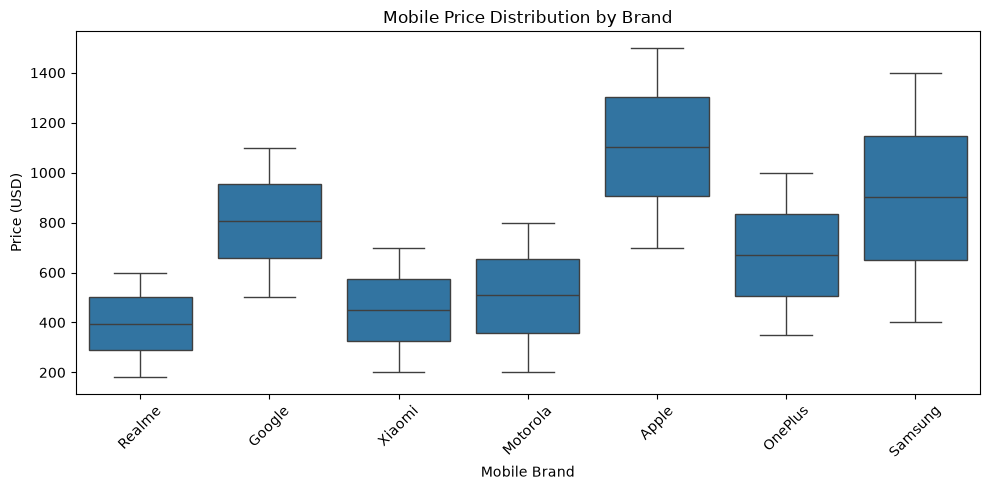

In [20]:

price_by_brand = (
    df_clean.groupby("brand", as_index=False)
    .agg(
        Average_Price_USD=("price_usd", "mean"),
        Median_Price_USD=("price_usd", "median")
    )
    .sort_values("Median_Price_USD", ascending=False)
)

display(price_by_brand.round(2))

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_clean,
    x="brand",
    y="price_usd"
)

plt.title("Mobile Price Distribution by Brand")
plt.xlabel("Mobile Brand")
plt.ylabel("Price (USD)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [21]:

# Calculate the percentage of positive reviews
def positive_review_percentage(series):
    valid_sentiments = series.dropna()

    if len(valid_sentiments) == 0:
        return np.nan

    return (
        valid_sentiments.str.strip()
        .str.lower()
        .eq("positive")
        .mean() * 100
    )


# Aggregate reviews into one row per mobile product
product_df = (
    df_clean
    .groupby(["brand", "model"], as_index=False)
    .agg(
        median_price_usd=("price_usd", "median"),
        average_rating=("rating", "mean"),
        battery_rating=("battery_life_rating", "mean"),
        camera_rating=("camera_rating", "mean"),
        performance_rating=("performance_rating", "mean"),
        design_rating=("design_rating", "mean"),
        display_rating=("display_rating", "mean"),
        average_helpful_votes=("helpful_votes", "mean"),
        review_count=("review_id", "count"),
        positive_review_percentage=(
            "sentiment",
            positive_review_percentage
        )
    )
)

print("Product-level dataset created!")
print("Number of products:", len(product_df))
print("Number of columns:", len(product_df.columns))

display(product_df.head(10))


Product-level dataset created!
Number of products: 22
Number of columns: 12


,brand,model,median_price_usd,average_rating,battery_rating,camera_rating,performance_rating,design_rating,display_rating,average_helpful_votes,review_count,positive_review_percentage
0,Apple,iPhone 13,1106.38,3.158239,2.754952,2.754952,2.765139,2.765139,2.710243,3.743067,1767,56.710214
1,Apple,iPhone 14,1094.51,3.185731,2.738255,2.781879,2.723714,2.773490,2.758949,3.690716,1788,56.880190
2,Apple,iPhone 15 Pro,1102.27,3.083924,2.677635,2.707195,2.661461,2.675404,2.691021,3.570552,1793,53.478774
3,Apple,iPhone SE,1101.03,3.101814,2.727728,2.703786,2.732183,2.690980,2.735523,3.575724,1796,54.587960
4,Google,Pixel 6,808.53,3.119037,2.712064,2.709962,2.689786,2.706179,2.715427,3.691047,2379,56.073944
5,Google,Pixel 7a,809.44,3.126015,2.715964,2.732172,2.725689,2.721232,2.748784,3.620746,2468,55.144558
6,Google,Pixel 8,799.52,3.129132,2.731881,2.715543,2.691244,2.743611,2.737746,3.600335,2387,54.942630
7,Motorola,Edge 50,514.92,3.092576,2.674730,2.701512,2.704536,2.688553,2.707559,3.631533,2315,54.424576
8,Motorola,Moto G Power,505.34,3.128399,2.715015,2.706083,2.716291,2.716291,2.719268,3.646533,2351,55.895390
9,Motorola,Razr 40,511.44,3.108497,2.713152,2.683925,2.730271,2.724843,2.724008,3.632985,2395,53.605981


In [22]:

print("Missing values in product-level dataset:")

display(
    product_df.isnull().sum()
    .to_frame("Missing_Count")
    .query("Missing_Count > 0")
)

print("\nProduct dataset information:")
product_df.info()


Missing values in product-level dataset:


,Missing_Count



Product dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   brand                       22 non-null     str    
 1   model                       22 non-null     str    
 2   median_price_usd            22 non-null     float64
 3   average_rating              22 non-null     float64
 4   battery_rating              22 non-null     float64
 5   camera_rating               22 non-null     float64
 6   performance_rating          22 non-null     float64
 7   design_rating               22 non-null     float64
 8   display_rating              22 non-null     float64
 9   average_helpful_votes       22 non-null     float64
 10  review_count                22 non-null     int64  
 11  positive_review_percentage  22 non-null     float64
dtypes: float64(9), int64(1), str(2)
memory usage: 2.2 KB


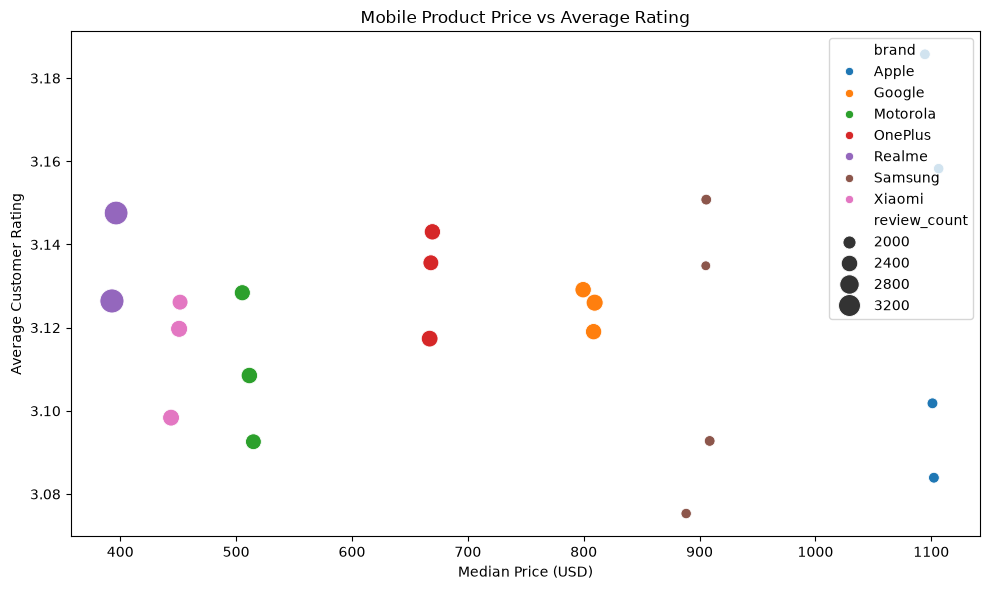

In [23]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=product_df,
    x="median_price_usd",
    y="average_rating",
    hue="brand",
    size="review_count",
    sizes=(50, 300)
)

plt.title("Mobile Product Price vs Average Rating")
plt.xlabel("Median Price (USD)")
plt.ylabel("Average Customer Rating")
plt.tight_layout()
plt.show()


In [24]:

# Select numerical product features
clustering_features = [
    "median_price_usd",
    "average_rating",
    "battery_rating",
    "camera_rating",
    "performance_rating",
    "design_rating",
    "display_rating"
]

X = product_df[clustering_features].copy()

print("Selected features:")
print(clustering_features)

print("\nFeature matrix shape:", X.shape)

display(X.head())


Selected features:
['median_price_usd', 'average_rating', 'battery_rating', 'camera_rating', 'performance_rating', 'design_rating', 'display_rating']

Feature matrix shape: (22, 7)


,median_price_usd,average_rating,battery_rating,camera_rating,performance_rating,design_rating,display_rating
0,1106.38,3.158239,2.754952,2.754952,2.765139,2.765139,2.710243
1,1094.51,3.185731,2.738255,2.781879,2.723714,2.773490,2.758949
2,1102.27,3.083924,2.677635,2.707195,2.661461,2.675404,2.691021
3,1101.03,3.101814,2.727728,2.703786,2.732183,2.690980,2.735523
4,808.53,3.119037,2.712064,2.709962,2.689786,2.706179,2.715427


In [25]:

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=clustering_features,
    index=product_df.index
)

print("Feature scaling completed!")

display(X_scaled_df.head())


Feature scaling completed!


,median_price_usd,average_rating,battery_rating,camera_rating,performance_rating,design_rating,display_rating
0,1.537585,1.389708,1.844734,1.441951,1.391390,1.753676,-0.347803
1,1.488848,2.467440,1.019224,2.483244,0.179942,2.037855,1.547464
2,1.520710,-1.523556,-1.977878,-0.404846,-1.640591,-1.299817,-1.095817
3,1.515618,-0.822255,0.498771,-0.536653,0.427612,-0.769807,0.635920
4,0.314654,-0.147081,-0.275692,-0.297824,-0.812262,-0.252610,-0.146105


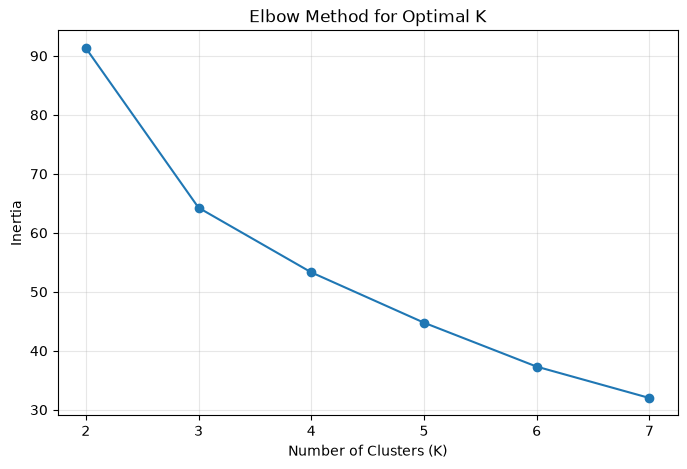

In [26]:

inertia_values = []
k_values = range(2, 8)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    model.fit(X_scaled)

    inertia_values.append(model.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.show()


In [27]:

silhouette_results = []

for k in range(2, 8):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_results.append({
        "Number_of_Clusters": k,
        "Silhouette_Score": score
    })

silhouette_df = pd.DataFrame(silhouette_results)

display(
    silhouette_df.sort_values(
        "Silhouette_Score",
        ascending=False
    ).round(4)
)


,Number_of_Clusters,Silhouette_Score
0,2,0.3696
1,3,0.3105
4,6,0.2240
2,4,0.2201
5,7,0.2115
3,5,0.2068


In [28]:

optimal_k = 4

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=20
)

product_df["cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed!")

print("\nProducts in each cluster:")
display(
    product_df["cluster"]
    .value_counts()
    .sort_index()
)


K-Means clustering completed!

Products in each cluster:


cluster
0    7
1    3
2    3
3    9
Name: count, dtype: int64

In [29]:

cluster_summary = (
    product_df.groupby("cluster")
    .agg(
        Product_Count=("model", "count"),
        Average_Price_USD=("median_price_usd", "mean"),
        Average_Rating=("average_rating", "mean"),
        Battery_Rating=("battery_rating", "mean"),
        Camera_Rating=("camera_rating", "mean"),
        Performance_Rating=("performance_rating", "mean"),
        Design_Rating=("design_rating", "mean"),
        Display_Rating=("display_rating", "mean")
    )
    .round(2)
)

display(cluster_summary)


,Product_Count,Average_Price_USD,Average_Rating,Battery_Rating,Camera_Rating,Performance_Rating,Design_Rating,Display_Rating
cluster,,,,,,,,
0,7,557.41,3.11,2.71,2.70,2.71,2.70,2.71
1,3,966.48,3.08,2.69,2.68,2.66,2.68,2.67
2,3,1035.56,3.16,2.74,2.76,2.75,2.76,2.73
3,9,688.19,3.13,2.73,2.73,2.74,2.72,2.74


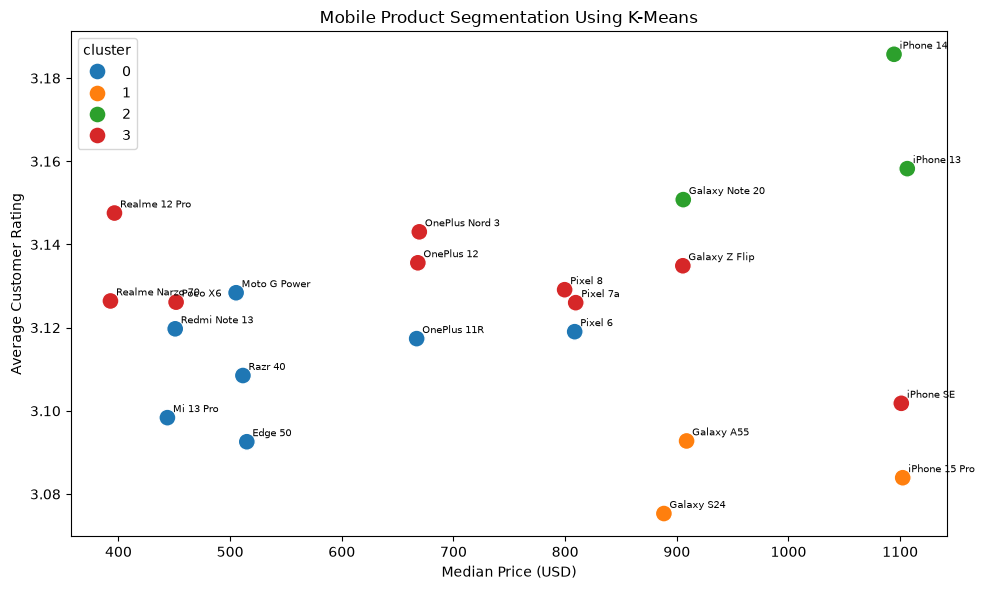

In [30]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=product_df,
    x="median_price_usd",
    y="average_rating",
    hue="cluster",
    palette="tab10",
    s=150
)

for _, row in product_df.iterrows():
    plt.annotate(
        row["model"],
        (
            row["median_price_usd"],
            row["average_rating"]
        ),
        fontsize=7,
        xytext=(4, 4),
        textcoords="offset points"
    )

plt.title("Mobile Product Segmentation Using K-Means")
plt.xlabel("Median Price (USD)")
plt.ylabel("Average Customer Rating")
plt.tight_layout()
plt.show()


In [31]:

# Calculate pairwise cosine similarity
similarity_matrix = cosine_similarity(X_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=product_df.index,
    columns=product_df.index
)

print("Similarity matrix shape:", similarity_df.shape)
print("Recommendation similarity matrix created!")

display(similarity_df.iloc[:5, :5].round(3))


Similarity matrix shape: (22, 22)
Recommendation similarity matrix created!


,0,1,2,3,4
0,1.000,0.797,-0.561,0.043,-0.556
1,0.797,1.000,-0.515,-0.109,-0.378
2,-0.561,-0.515,1.000,0.292,0.831
3,0.043,-0.109,0.292,1.000,0.170
4,-0.556,-0.378,0.831,0.170,1.000


In [32]:

def recommend_mobile(selected_model, top_n=5):

    # Find the selected product
    matches = product_df.index[
        product_df["model"] == selected_model
    ].tolist()

    if not matches:
        raise ValueError(
            f"Model '{selected_model}' was not found."
        )

    product_index = matches[0]

    # Get similarity scores for the selected product
    scores = similarity_df.loc[product_index]

    # Rank products by similarity
    ranked_indices = scores.sort_values(
        ascending=False
    ).index

    # Exclude the selected product itself
    ranked_indices = [
        idx for idx in ranked_indices
        if idx != product_index
    ]

    recommended_indices = ranked_indices[:top_n]

    recommendations = product_df.loc[
        recommended_indices,
        [
            "brand",
            "model",
            "median_price_usd",
            "average_rating",
            "cluster"
        ]
    ].copy()

    recommendations["similarity_score"] = [
        scores.loc[idx]
        for idx in recommended_indices
    ]

    return recommendations.reset_index(drop=True)


print("Recommendation function created successfully!")


Recommendation function created successfully!


In [33]:

recommendations = recommend_mobile(
    selected_model="Pixel 7a",
    top_n=5
)

print("Recommended mobile phones for Pixel 7a:")
display(recommendations.round(3))


Recommended mobile phones for Pixel 7a:


,brand,model,median_price_usd,average_rating,cluster,similarity_score
0,Apple,iPhone 14,1094.510,3.186,2,0.689
1,Samsung,Galaxy Z Flip,905.380,3.135,3,0.671
2,Realme,Realme 12 Pro,396.410,3.148,3,0.486
3,Samsung,Galaxy Note 20,905.775,3.151,2,0.414
4,Google,Pixel 8,799.520,3.129,3,0.404


In [36]:

import ipywidgets as widgets
from IPython.display import display, clear_output

model_dropdown = widgets.Dropdown(
    options=product_df["model"].tolist(),
    description="Mobile:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="400px")
)

output = widgets.Output()

def show_recommendations(change):
    if change["name"] == "value":
        with output:
            clear_output(wait=True)

            print(
                "Recommendations for:",
                change["new"]
            )

            display(
                recommend_mobile(
                    selected_model=change["new"],
                    top_n=5
                ).round(3)
            )

model_dropdown.observe(
    show_recommendations,
    names="value"
)

display(model_dropdown, output)

# Display recommendations for the initial selection
with output:
    print("Recommendations for:", model_dropdown.value)
    display(
        recommend_mobile(
            selected_model=model_dropdown.value,
            top_n=5
        ).round(3)
    )


Dropdown(description='Mobile:', layout=Layout(width='400px'), options=('iPhone 13', 'iPhone 14', 'iPhone 15 Pr…

Output()